In [1]:
import matplotlib.pyplot as plt
import xarray as xr
import numpy as np
import pandas as pd
# from itertools import cycle, product
from pathlib import Path

%cd /g/data/w42/dr6273/work/wind_drought/
import src.wind as wind
import src.utils as utils
import src.read as read

/g/data/w42/dr6273/work/wind_drought


In [2]:
%load_ext autoreload
%autoreload 2

#### Wind drought (WDD) data

- ERA5 and BARRA-R2
- capacity factor
- MJJ 10th percentile drought-day threshold
- weighted SC30 scenario for NEM/SE region

In [3]:
wdd_dict = {}
for dataset in ["ERA5", "BARRA-R2"]:
    wdd_dict[dataset] = {}

    for variable in ["capacity_factor"]:
        wdd_dict[dataset][variable] = {}

        for region in ["NEM", "SE", "SWIS", "NWIS"]:
            
            if region in ["NEM", "SE"]:
                for scenario in ["SC30"]:
                    wdd_dict[dataset][variable][region+"-"+scenario] = {}

                    for averaging in ["weighted"]:
                        da = read.load_wind(dataset, variable, region, scenario, averaging)[variable]
                        pctl = utils.sel_month(da, [5, 6, 7]).quantile(0.1, "time")
                        wdd = wind.calc_wdd_timeseries(da, pctl)
                        
                        wdd_dict[dataset][variable][region+"-"+scenario][averaging] = wdd

            else:
                da = read.load_wind(dataset, variable, region)[variable]
                pctl = utils.sel_month(da, [5, 6, 7]).quantile(0.1, "time")
                wdd = wind.calc_wdd_timeseries(da, pctl)
                
                wdd_dict[dataset][variable][region] = wdd

#### Longest droughts

In [4]:
def get_droughts(da):
    """Return dataframe of drought duration, start date and end date"""
    years = da.time.dt.year.values
    df = pd.DataFrame(index=years)
    df['WDD'] = da.values.astype('int32')
    df['start_date'] = pd.to_datetime(da.time.dt.strftime('%Y-%m-%d'))
    df['end_date'] = pd.to_datetime(da.time.dt.strftime('%Y-%m-%d')) + pd.to_timedelta(df['WDD'] - 1, unit='D')
    return df.set_index('start_date')

In [5]:
events_dict = utils.map_leaves(
    wdd_dict,
    lambda value: get_droughts(value)
)

In [6]:
events_dict['BARRA-R2']['capacity_factor']['NEM-SC30']['weighted']

,WDD,end_date
start_date,,
1979-03-08,1,1979-03-08
1979-04-06,1,1979-04-06
1979-05-08,2,1979-05-09
1979-05-17,2,1979-05-18
1979-07-18,1,1979-07-18
...,...,...
2025-05-13,4,2025-05-16
2025-06-11,2,2025-06-12
2025-06-26,4,2025-06-29


In [9]:
def split_droughts(df, wdd_col="WDD", q1=0.95, q2=0.99):
    q_low, q_high = df[wdd_col].quantile([q1, q2])
    
    print("n events:", len(df))
    print("low WDD thresh:", q_low, "high WDD thresh:", q_high)

    top = df[df[wdd_col] >= q_high].sort_values(wdd_col, ascending=False)
    other = df[
        (df[wdd_col] >= q_low) & (df[wdd_col] < q_high)
    ].sort_values(wdd_col, ascending=False)

    print("n top events:", len(top), "n other events:", len(other))
    print()

    return {"top": top, "other": other}

In [8]:
subset_dict = utils.map_leaves(events_dict, split_droughts)

n events: 685
low WDD thresh: 3.0 high WDD thresh: 5.0
n top events: 9 n other events: 45

n events: 696
low WDD thresh: 3.0 high WDD thresh: 4.0499999999999545
n top events: 7 n other events: 42

n events: 586
low WDD thresh: 3.0 high WDD thresh: 4.0
n top events: 8 n other events: 26

n events: 621
low WDD thresh: 3.0 high WDD thresh: 6.0
n top events: 9 n other events: 79

n events: 516
low WDD thresh: 3.0 high WDD thresh: 5.0
n top events: 9 n other events: 40

n events: 553
low WDD thresh: 3.0 high WDD thresh: 5.0
n top events: 8 n other events: 39

n events: 515
low WDD thresh: 3.0 high WDD thresh: 3.0
n top events: 33 n other events: 0

n events: 634
low WDD thresh: 4.0 high WDD thresh: 6.0
n top events: 10 n other events: 23



### Synoptic Weather Types

In [10]:
# Australian Synoptic Weather Type data from forked repository
swt = pd.read_csv(
    "../Australian-synoptic-weather-types/SWT_climatology/SWT_climatology.csv",
    index_col=0,
    parse_dates=True
)

In [19]:
print(swt.head())

           assigned_SWT
time                   
1952-01-01         WH-A
1952-01-02         TH-A
1952-01-03         FH-A
1952-01-04        WCT-A
1952-01-05        WCT-A


In [11]:
ordered_SWTs = [
    "WH-A", "WH-B", "WH-C", "WH-D",
    "CH-A", "CH-B",
    "EH-A", "EH-B", "EH-C", "EH-D", "EH-E",
    "TH-A", "TH-B", "TH-C",
    "FH-A", "FH-B", "FH-C",
    "WCT-A", "WCT-B",
    "COL-A", "COL-B", "COL-C", "COL-D", "COL-E", "COL-F",
    "AM-A", "AM-B", "AM-C", "AM-D", "AM-E"
]

In [12]:
missing_values = set(ordered_SWTs) - set(swt["assigned_SWT"].dropna().unique())

if missing_values:
    print("Missing from swt:", sorted(missing_values))
else:
    print("All ordered_SWTs are present in swt.")

All ordered_SWTs are present in swt.


In [13]:
# Plotting bars for each SWT category in the groups
swt_colors=[
    (134/255,0/255,34/255),(241/255,0/255,241/255),(255/255,134/255,255/255),(255/255,241/255,255/255), #Pink WH
    (255/255,204/255,51/255),(255/255,245/255,204/255), #Yellow CH
    (153/255,15/255,15/255),(178/255,44/255,44/255),(204/255,81/255,81/255),(229/255,126/255,126/255),(255/255,178/255,178/255), #Red EH
    (153/255,84/255,15/255),(204/255,142/255,81/255),(255/255,216/255, 178/255), #Brown TH
    (107/255,153/255,15/255),(163/255,204/255,81/255),(195/255,229/255,126/255), #Green FH (133/255,178/255,44/255),
    (66/255,44/255,178/255),(143/255,126/255,229/255), #Purple WCT
    (5/255,67/255,113/255),(15/255,107/255,153/255),(44/255,133/255,178/255),(81/255,163/255,204/255),(126/255,195/255,229/255),(178/255,229/255,255/255), #Blue COL
    (0/255,60/255,48/255),(1/255,102/255,95/255),(53/255,151/255,143/255),(128/255,205/255,193/255),(199/255,234/255,229/255)
]

In [14]:
colour_by_swt = dict(zip(ordered_SWTs, swt_colors))

Get SWT occurrences during droughts

In [20]:
def get_swt_distribution(df, swt, ordered_swts, normalize=False):
    distributions = {}

    for start, end in zip(df.index, df["end_date"]):
        event_swts = swt.loc[start:end, "assigned_SWT"]

        distributions[start] = (
            event_swts
            .value_counts(normalize=normalize)
            .reindex(ordered_swts, fill_value=0)
        )

    return pd.DataFrame(distributions).T.reindex(columns=ordered_swts)

In [21]:
swt_distributions = utils.map_leaves(
    subset_dict,
    lambda df: get_swt_distribution(df, swt, ordered_SWTs),
)

In [32]:
def plot_swt_by_event(ax, events, region, wdd_col="WDD"):
    """ Plot SWT occurrences for each event """
    from matplotlib.patches import Patch
    import matplotlib.dates as mdates

    for event_number, (start, end) in enumerate(zip(events.index, events['end_date'])):
        event_swts = swt.loc[start:end, "assigned_SWT"]

        bottom = 0

        for event_date, swt_name in event_swts.items():
            ax.bar(
                event_number,
                height=1,
                bottom=bottom,
                width=0.8,
                color=colour_by_swt[swt_name],
                edgecolor="gray",
                linewidth=0.5
            )
    
            bottom += 1

    ax.set_xlabel("Event start date")
    ax.set_ylabel("Event day")

    # Legend
    event_swt_names = set()
    
    for start, row in events.iterrows():
        end = row["end_date"]
    
        event_swt_names.update(
            swt.loc[start:end, "assigned_SWT"]
            .dropna()
            .unique()
        )
    
    legend_handles = [
        Patch(
            facecolor=colour_by_swt[swt_name],
            label=swt_name
        )
        for swt_name in ordered_SWTs
        if swt_name in event_swt_names
    ]
    
    ax.legend(
        handles=legend_handles,
        bbox_to_anchor=(0.51, 1.03),
        loc="upper left",
        # title="SWT",
        ncols=4,
        fontsize=9,
        frameon=True
    )

    # Axis details
    labels = events.index.strftime("%Y-%m-%d")
    ax.set_xticks(range(len(events)))
    ax.set_xticklabels(labels)
    ax.tick_params(axis='x', labelrotation=45)

    ax.set_yticks(np.arange(0.5, 11, 2))
    ax.set_yticklabels(range(1, 12, 2))
    
    min_len = str(events.iloc[-1][wdd_col])
    ax.set_title('a) ' + region + r' SWT occurrences for each wind drought $\geq $' + min_len + ' days duration', loc='left', fontsize=10)

In [37]:
d = swt_distributions['BARRA-R2']['capacity_factor']['NEM-SC30']['weighted']['top']

In [57]:
import calendar

In [64]:
"".join([calendar.month_name[i][0] for i in np.unique(d.index.month)])

'AMJJ'

In [71]:
def plot_swt_hist(ax, distributions, region, show_other=True):
    """ histogram of SWT occurrences during all events """

    top_swt_counts = (
        distributions['top']
        .sum(axis=0)
        .reindex(ordered_SWTs, fill_value=0)
    )
    
    other_swt_counts = (
        distributions['other']
        .sum(axis=0)
        .reindex(ordered_SWTs, fill_value=0)
    )
    
    # climatological counts during months featured in top droughts
    months = np.unique(distributions["top"].index.month)
    month_abbrevs = "".join([calendar.month_name[i][0] for i in months])
    swt_subset = swt[swt.index.month.isin(months)]
    clim_counts = (
        swt_subset["assigned_SWT"]
        .value_counts()
        .reindex(ordered_SWTs, fill_value=0)
    )
    
    # Convert to frequencies
    top_event_freq = top_swt_counts / top_swt_counts.sum()
    other_event_freq = other_swt_counts / other_swt_counts.sum()
    clim_freq = clim_counts / clim_counts.sum()
    
    x = range(len(ordered_SWTs))
    
    ax.bar(
        x,
        top_event_freq,
        color=[colour_by_swt[swt] for swt in ordered_SWTs],
        alpha=0.8,
        label="Top events",
    )

    if show_other:
        ax.plot(
            x,
            other_event_freq,
            color="gray",
            marker="s",
            ls="--",
            markersize=5,
            linewidth=.8,
            label="Other events",
        )
        
    ax.plot(
        x,
        clim_freq,
        color="black",
        marker="o",
        markersize=5,
        linewidth=.8,
        label=month_abbrevs + " climatology",
    )
    
    ax.set_xticks(x)
    ax.set_xticklabels(ordered_SWTs, rotation=45, ha="right")
    ax.set_xlabel('SWT')
    ax.set_ylabel("Relative frequency [-]")
    ax.legend(fontsize=9)

    min_len = str(distributions['top'].iloc[-1].sum())
    ax.set_title('b) ' + region + r' SWT occurrences for all wind droughts $\geq $' + min_len + ' days duration', loc='left', fontsize=10)

In [74]:
dataset.lower()

'era5'

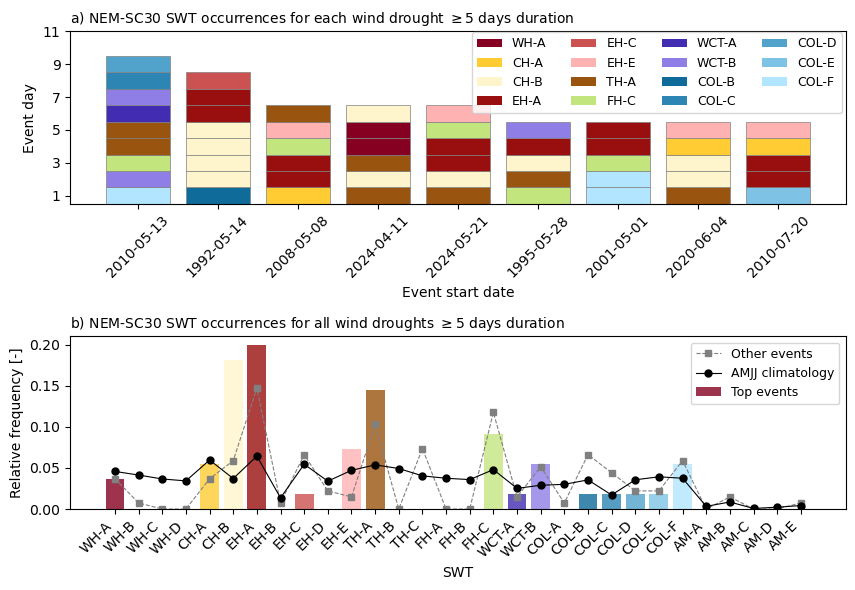

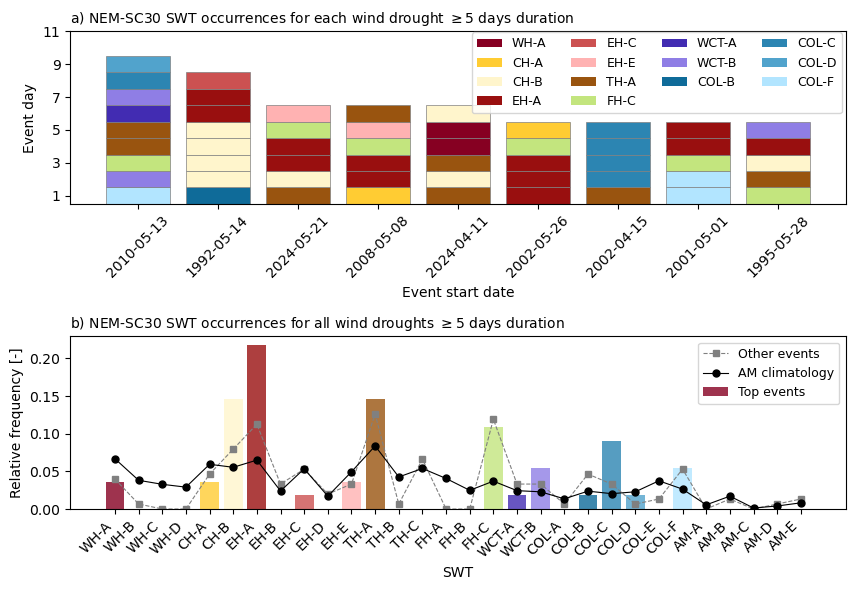

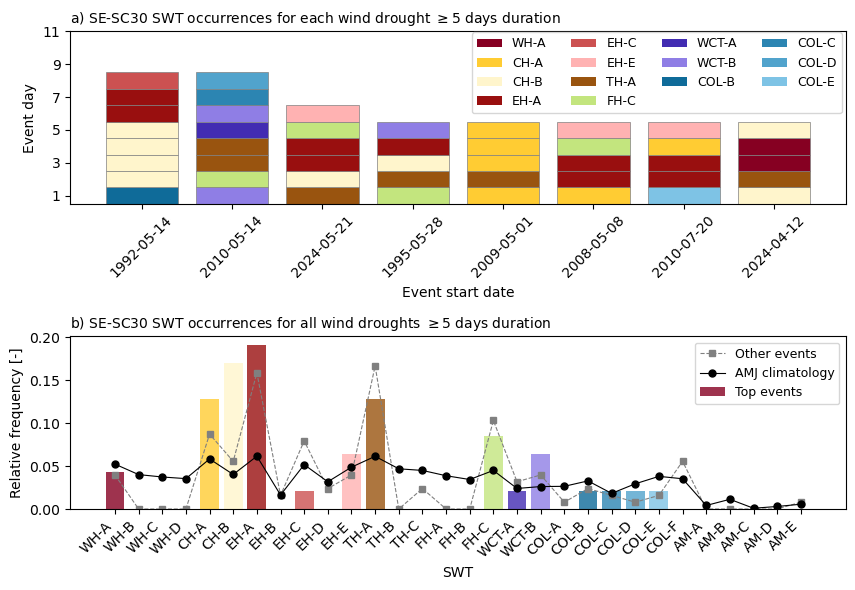

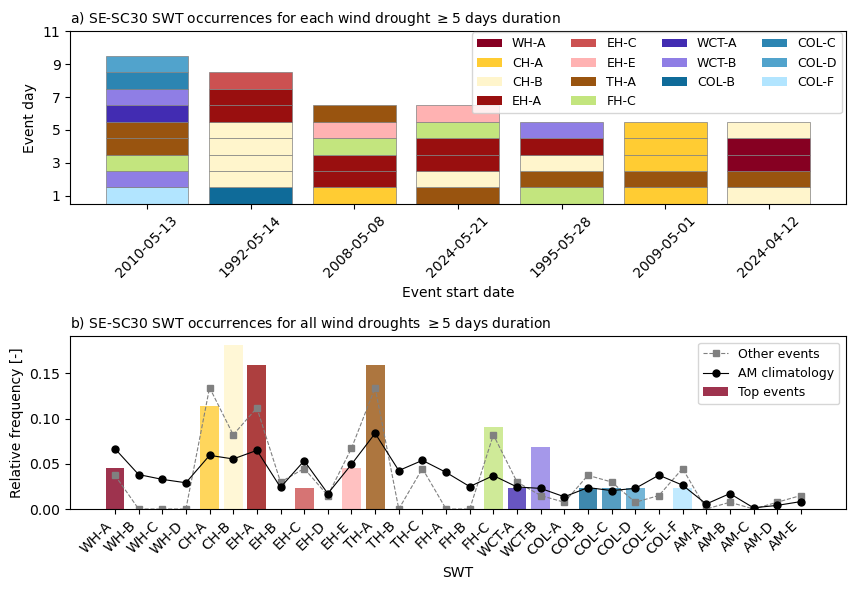

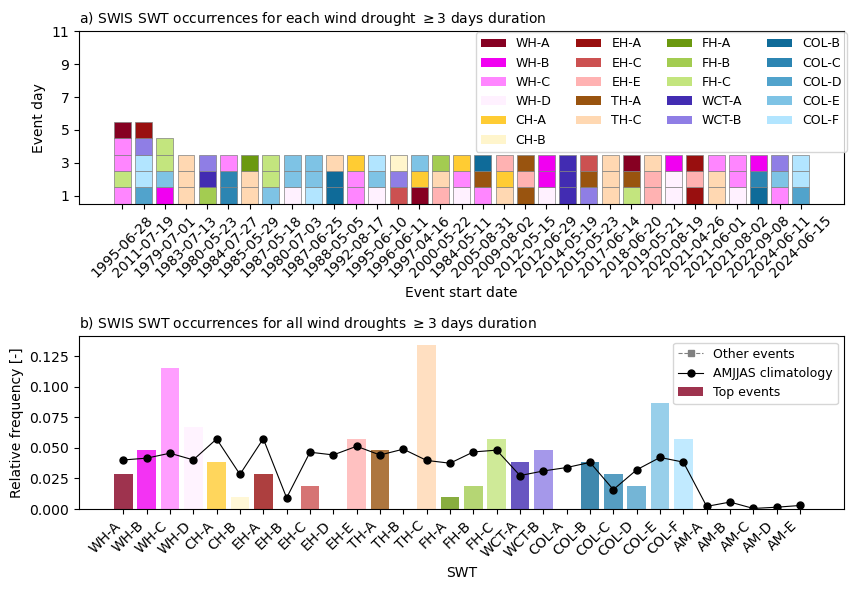

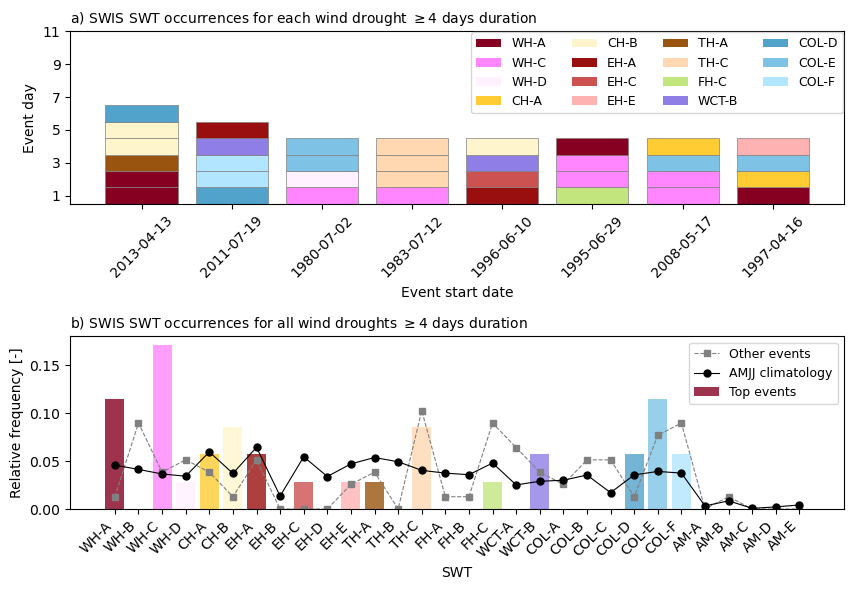

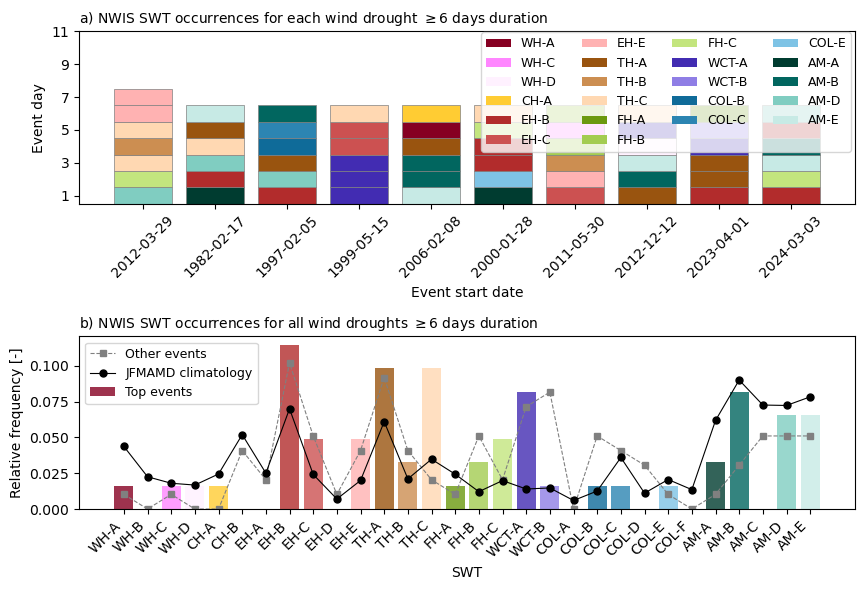

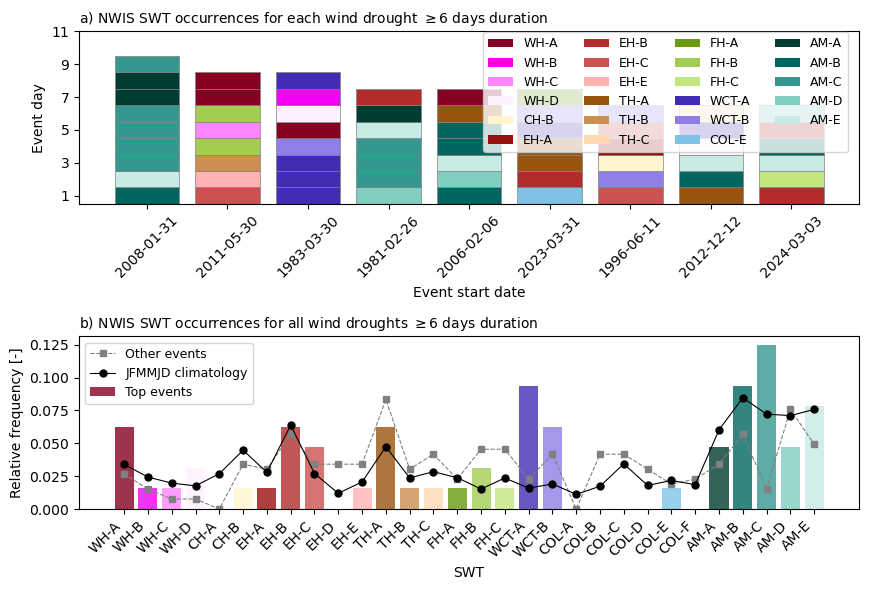

In [76]:
for region in ["NEM-SC30", "SE-SC30", "SWIS", "NWIS"]:
    for dataset in ["BARRA-R2", "ERA5"]:
        
        if region in ["SWIS", "NWIS"]:
            events = subset_dict[dataset]["capacity_factor"][region]["top"]
            distributions = swt_distributions[dataset]["capacity_factor"][region]
        else:
            events = subset_dict[dataset]["capacity_factor"][region]["weighted"]["top"]
            distributions = swt_distributions[dataset]["capacity_factor"][region]["weighted"]
            
        fig, axes = plt.subplots(2, 1, figsize=(9, 6))
        
        ax = axes[0]
        plot_swt_by_event(ax, events, region)
        
        ax = axes[1]
        plot_swt_hist(ax, distributions, region, show_other=True)
        
        plt.tight_layout()

        plt.savefig("figures/events_swt_"+region.lower()+"_"+dataset.lower()+".png")